In [1]:
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from gwlens.tools import halo
import astropy.units as u

plotting.apply_figure_style()


### Halo

100000.0
NFW Halo Summary:
  M_200       = 1.00e+05 solMass 
  c           = 82.62966323168075
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.95746 kpc
  r_s         = 0.01159 kpc 
  rho_s       = 1.49e+09 solMass / kpc3 

104761.57527896641
NFW Halo Summary:
  M_200       = 1.05e+05 solMass 
  c           = 82.13149347873156
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.97242 kpc
  r_s         = 0.01184 kpc 
  rho_s       = 1.46e+09 solMass / kpc3 

109749.87654930567
NFW Halo Summary:
  M_200       = 1.10e+05 solMass 
  c           = 81.63632716417294
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 solMass / kpc3 
  r_200       = 0.98762 kpc
  r_s         = 0.01210 kpc 
  rho_s       = 1.44e+09 solMass / kpc3 

114975.69953977356
NFW Halo Summary:
  M_200       = 1.15e+05 solMass 
  c           = 81.144146180438
  H_0         = 70.0 km / (Mpc s) 
  rho_c       = 135.99295 sol

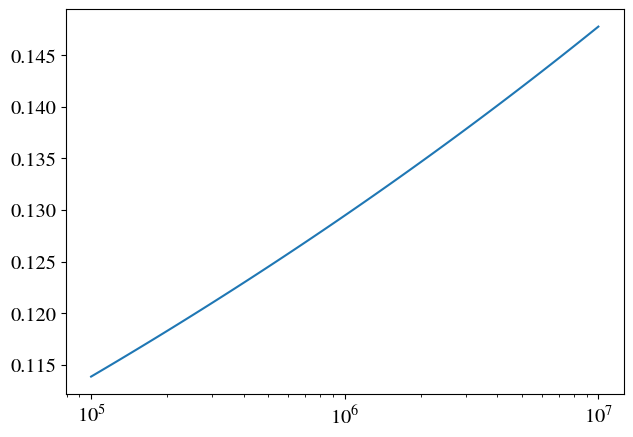

In [33]:
mass =  np.logspace(5,7,100)
k_value = []
for m in mass:
    print(m)
    Halo = halo.NFW(M200 = m, zl = 0.5)
    Halo.summary()

    k_val = Halo.scaling_ratio(zs = 1.0)
    k_value.append(k_val)
    #k_val =  Halo.scaling_ratio(Dl = 10*u.kpc, Ds= 20 *u.kpc, Dls = 10* u.kpc)
print("Normalization for GWLENS",k_val)
print("Normalization for GLoW:",1/k_val)
plt.semilogx(mass,k_value)


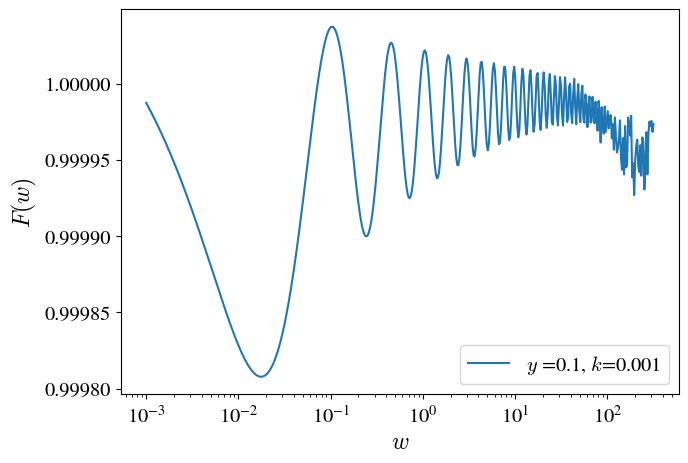

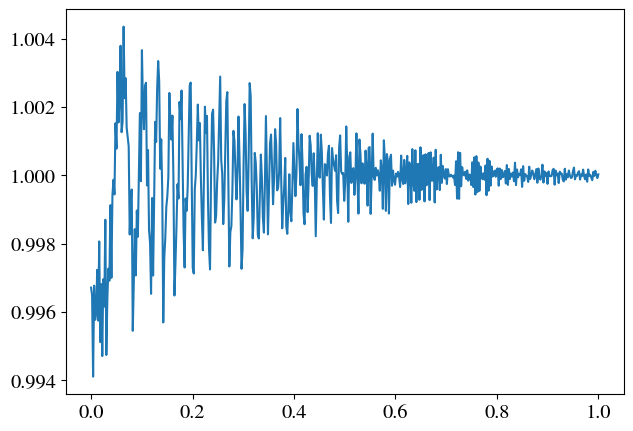

In [3]:
lens = nfw.NFW1()
w = np.logspace(-3,2.5,500)
y = np.linspace(0,1,500)

y_fixed = 0.1
w_fixed = 1868

k = 0.001 #k_val.value

Fw = np.array([lens.F_eps_NFW(wi, y_fixed, k, N=7000, eps=0.002) for wi in w])
Fy = np.array([lens.F_eps_NFW(w_fixed,yi,k, N =5000, eps=0.002) for yi in y])

plt.semilogx(w, np.abs(Fw), label=f"$y$ ={y_fixed}, $k$={k}")
plt.xlabel("$w$")
plt.ylabel("$F(w)$")
plt.legend()
plt.show()

plt.plot(y,np.abs(Fy))

In [30]:
from scipy.special import jv
def potential(k, x):
    u = k * x
    return np.where(
        u <= 1,
        0.5 * (np.log(np.maximum(u, 1e-300) / 2)**2
            - np.arctanh(np.sqrt(np.maximum(1 - u**2, 0)))**2),
        0.5 * (np.log(u / 2)**2
            + np.arctan(np.sqrt(np.maximum(u**2 - 1, 0)))**2)
    )   

def F_eps_NFW(w, y1,k,y2=0, N=5000, eps=0.002):

        """
        Docstring for F_eps_NFW
        
        :param w: Dimensionless frequency
        :param y1: Impact parameter 
        :param y2: Impact parameter (set to 0 )
        :param k: Normalization constant , consistent with GLoW NFW normalization
        :param N: Grid resolution
        :param eps: regulaization
        """ 
        y   = np.sqrt(y1**2 + y2**2)
        w_c = w * (1.0 + 1j * eps)
        L   = 100 #max(y, 0.0) + max(3.5, 4.0 / np.sqrt(w * eps), 2.5 * k)
        
        r   = np.linspace(0, L, N + 1)[1:]
        dr  = r[1] - r[0]

        psi       = potential(k, r)
        phi_r     = 0.5 * (r**2 + y**2) - psi
        J0        = jv(0, w_c * y * r)
        integrand = np.exp(1j * w_c * phi_r) * J0 * r
        return (w / 1j) * np.sum(integrand) * dr

### comparing the Fourier Integral and $\epsilon$- Regularization technique in GWLENS 

k=1.4, y=0.1 | ε-reg: 2.0s  GLoW: 0.0s
k=1.4, y=0.2 | ε-reg: 1.7s  GLoW: 0.0s
k=1.4, y=1.0 | ε-reg: 1.3s  GLoW: 0.0s
k=1.4, y=5.0 | ε-reg: 1.2s  GLoW: 0.0s
k=3.5, y=0.1 | ε-reg: 2.0s  GLoW: 0.0s
k=3.5, y=0.2 | ε-reg: 1.7s  GLoW: 0.0s
k=3.5, y=1.0 | ε-reg: 1.3s  GLoW: 0.0s
k=3.5, y=5.0 | ε-reg: 1.2s  GLoW: 0.0s


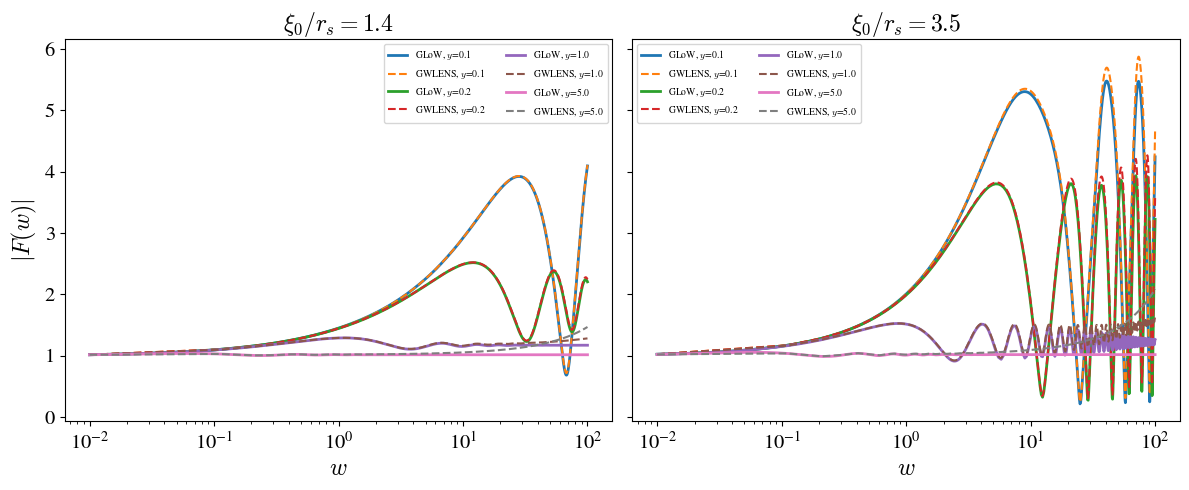

Epsilon_finished in: 1.1664276123046875
Glow_finished in: 0.0023386478424072266


In [35]:
from mpmath import mp
import time
from glow import time_domain_c, freq_domain_c, lenses
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
import gc

plotting.apply_figure_style()
mp.dps = 50  # reduce from 400 unless you specifically need that precision

# --- Parameters ---
k_values = [1.4,3.5]          # ← add/remove k values here
y_fixed  = [0.1, 0.2, 1.0, 5.0]
w_val    = np.linspace(0.01, 100, 1000)
nfw_lens = nfw.NFW1()

# --- Subplots: one panel per k_fixed ---
fig, axes = plt.subplots(1, len(k_values), figsize=(6 * len(k_values), 5), sharey=True)

if len(k_values) == 1:          # ensure axes is always iterable
    axes = [axes]

for ax, k_fixed in zip(axes, k_values):
    for yi in y_fixed:

        # --- GWLENS epsilon regularisation ---
        start_eps = time.time()
        F_eps = np.array([
            nfw_lens.F_eps_NFW(w=wi, y1=yi, k=k_fixed, N=8000, eps=0.002)
            for wi in w_val
        ])
        end_eps = time.time()

        # --- GLoW ---
        start_glow = time.time()
        Psi_cls = lenses.Psi_NFW
        Psi_tmp = Psi_cls()
        p_phys_default, p_prec_default = Psi_tmp.default_params()

        p_phys = dict(p_phys_default)
        p_phys['name'] = 'NFW'
        p_phys['psi0'] = 1.0
        p_phys['xs']   = 1 / k_fixed

        p_prec = dict(p_prec_default)
        p_prec['eps_soft'] = 1e-15
        p_prec['eps_NFW']  = 0.001

        Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)
        It_nfw  = time_domain_c.It_SingleIntegral_C(Psi_nfw, yi)
        Fw_nfw  = freq_domain_c.Fw_FFT_C(It_nfw)
        w_glow  = Fw_nfw.w_grid

        ax.semilogx(w_glow, np.abs(Fw_nfw.eval_Fw(w_glow)),
                    lw=2, label=f"GLoW, $y$={yi}")
        ax.semilogx(w_val, np.abs(F_eps),
                    ls="--", label=f"GWLENS, $y$={yi}")

        end_glow = time.time()
        print(f"k={k_fixed}, y={yi} | ε-reg: {end_eps-start_eps:.1f}s  GLoW: {end_glow-start_glow:.1f}s")

        del It_nfw, Fw_nfw, Psi_nfw   # free C objects each iteration
        gc.collect()

    ax.set_xlabel("$w$")
    ax.set_title(f"$\\xi_0/r_s = {k_fixed}$")
    ax.legend(fontsize=7, ncol=2)

axes[0].set_ylabel("$|F(w)|$")
fig.tight_layout()
plt.savefig("NFW_comparison_lowk.png", bbox_inches="tight")
plt.show()

print("Epsilon_finished in:",end_eps-start_eps)
print("Glow_finished in:",end_glow-start_glow)

(1.00683713051466625438606100342744353318162009960116280541079395145477118582147610597314617220644624444743999753602115440855057140932826856827836716848934199759190364214541582486263724452473709176136385816219977683495282996030474546906606973144002062625011146187100699059834789010570658653819650325559818748135547754305579291394675852817860476580090560336354356933826284011572090189441744025574821501 - 0.003279946129030820352986094201761803879305786965669548209775079307395631344991218319066564811247141415485278337588415616922524486195710708804390752265808972462628932220877156577710402857570530433363822825123837390653612926481077382909904662826747703694516428643805864275787617802240102286689714158161634966151153648896812270856749458626447655918881850374142679684552166749638860524540172886736366119278j)


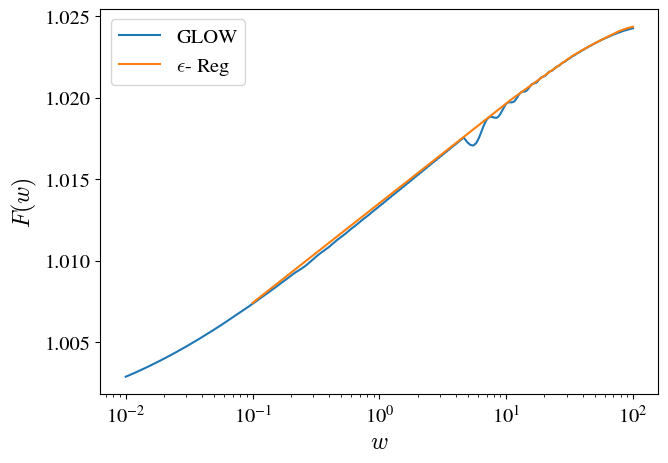

In [ ]:
It_nfw = time_domain_c.It_SingleIntegral_C(Psi_nfw, 0.1)
Fw_nfw = freq_domain_c.Fw_FFT_C(It_nfw)
w_glow = Fw_nfw.w_grid
plt.semilogx(w_glow,np.abs(Fw_nfw.eval_Fw(w_glow)),label="GLOW")
#plt.semilogx(w_val,np.abs(F_fi), label="Fourier-Integral")
plt.semilogx(w_val, np.abs(F_eps), label="$\epsilon$- Reg")
plt.legend()
plt.xlabel("$w$")
plt.ylabel("$F(w)$")


### Meshgrid plot


In [ ]:
w_val = np.logspace(-1,2,100)
y_val = np.linspace(0,5,100)

W,Y = np.meshgrid(w_val,y_val)
Z = np.zeros_like(W)


In [15]:
print(L)

NameError: name 'L' is not defined